# SONG `UMAP_dispersion`: static performance baseline

Source: commit `4c711c83502b235ae931f09ba785b86e21e769fd` on `UMAP_dispersion`. The [SONG paper](https://arxiv.org/abs/1912.04896) studies dimensionality reduction, incremental updates and robustness. This is a **small reproducible smoke benchmark**, not a reproduction of the paper's MNIST/Fashion-MNIST experiments.

This notebook measures elapsed fit and embedding time, neighborhood trustworthiness, 10-neighbor recall, cluster ARI and a five-fold kNN label probe. The probe uses a completed, transductive embedding; it is not out-of-sample accuracy. Each result is one warmed run, so small differences should not be treated as significant. The data are bundled with scikit-learn; no network download is needed. The SONG runs use 10 self-organization steps to keep this report practical; the constructor default is 100. The UMAP baseline uses its own default epoch budget, so its timing is contextual rather than a matched-compute comparison.

Run from the repository root with `NUMBA_NUM_THREADS=2 OPENBLAS_NUM_THREADS=2 .venv/bin/python -m jupyter ...` or execute cells in a kernel with `reports/requirements.txt` installed. The saved outputs below were generated on an Apple Silicon Mac with Python 3.11.15.

In [1]:
import os, sys, time, platform, warnings
from importlib.metadata import version
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.manifold import trustworthiness
from sklearn.neighbors import NearestNeighbors, KNeighborsClassifier
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, adjusted_mutual_info_score
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.decomposition import PCA
from umap import UMAP
from song.song import SONG

print('Python', sys.version.split()[0], '|', platform.platform(), '| NumPy', np.__version__, '| umap-learn', version('umap-learn'))
print('Numba threads', os.environ.get('NUMBA_NUM_THREADS', '(default)'), '| BLAS threads', os.environ.get('OPENBLAS_NUM_THREADS', '(default)'))
fig_dir = Path('reports/figures')
fig_dir.mkdir(parents=True, exist_ok=True)


/Users/damith/personal/SONG/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Python 3.11.15 | macOS-26.2-arm64-arm-64bit | NumPy 2.4.6 | umap-learn 0.5.12
Numba threads 2 | BLAS threads 2


In [2]:
# Warm Numba/UMAP compilation before timing. This is excluded from the table.
digits = load_digits()
X_warm = (digits.data[:80] / 16).astype(np.float32)
SONG(so_steps=2, final_vector_count=16, chunk_size=128, random_seed=42, dispersion_method='none').fit_transform(X_warm)
SONG(so_steps=2, final_vector_count=16, chunk_size=128, random_seed=42, dispersion_method='UMAP').fit_transform(X_warm)
UMAP(n_neighbors=15, n_epochs=11, random_state=42).fit_transform(X_warm)
print('JIT warm-up complete')

/Users/damith/personal/SONG/.venv/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


JIT warm-up complete


In [3]:
def neighborhood_recall(X, Y, k=10):
    hi = NearestNeighbors(n_neighbors=k+1).fit(X).kneighbors(return_distance=False)[:, :k]
    lo = NearestNeighbors(n_neighbors=k+1).fit(Y).kneighbors(return_distance=False)[:, :k]
    return float(np.mean([len(set(a) & set(b)) / k for a, b in zip(hi, lo)]))

def run_one(X, labels, size, method):
    start = time.perf_counter()
    if method.startswith('SONG'):
        mode = 'UMAP' if method == 'SONG + UMAP dispersion' else 'none'
        model = SONG(so_steps=10, final_vector_count=48, chunk_size=128, random_seed=42, dispersion_method=mode)
        model.fit(X)
        fit_s = time.perf_counter() - start
        Y = model.transform(X)
        prototypes = len(model.W)
    elif method == 'UMAP':
        model = UMAP(n_neighbors=15, min_dist=.1, random_state=42)
        Y = model.fit_transform(X)
        fit_s, prototypes = np.nan, np.nan
    else:
        model = PCA(n_components=2, random_state=42)
        Y = model.fit_transform(X)
        fit_s, prototypes = np.nan, np.nan
    total_s = time.perf_counter() - start
    assert Y.shape == (len(X), 2) and np.isfinite(Y).all()
    cv = StratifiedKFold(5, shuffle=True, random_state=42)
    accuracy = cross_val_score(KNeighborsClassifier(n_neighbors=5), Y, labels, cv=cv).mean()
    clusters = KMeans(n_clusters=10, n_init=10, random_state=42).fit_predict(Y)
    ari = adjusted_rand_score(labels, clusters)
    ami = adjusted_mutual_info_score(labels, clusters)
    return dict(size=size, method=method, fit_s=fit_s, transform_s=total_s-fit_s if np.isfinite(fit_s) else np.nan,
                total_s=total_s, trustworthiness=trustworthiness(X, Y, n_neighbors=10),
                neighbor_recall_10=neighborhood_recall(X, Y), kNN_probe_accuracy=float(accuracy),
                kmeans_ARI=float(ari), kmeans_AMI=float(ami), prototypes=prototypes), Y

rng = np.random.default_rng(42)
indices = rng.permutation(len(digits.data))
rows, embeddings = [], {}
methods = ['SONG core', 'SONG + UMAP dispersion', 'UMAP', 'PCA']
for size in (300, 600):
    X = (digits.data[indices[:size]] / 16).astype(np.float32)
    labels = digits.target[indices[:size]]
    for method in methods:
        row, Y = run_one(X, labels, size, method)
        rows.append(row)
        embeddings[(size, method)] = Y.copy()
        print(size, method, f"{row['total_s']:.2f}s", f"trust={row['trustworthiness']:.3f}", f"ARI={row['kmeans_ARI']:.3f}")
results = pd.DataFrame(rows)
display(results.round(3))
results.to_csv('reports/static_baseline.csv', index=False)


300 SONG core 0.01s trust=0.846 ARI=0.174
300 SONG + UMAP dispersion 0.04s trust=0.850 ARI=0.179


/Users/damith/personal/SONG/.venv/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


300 UMAP 0.22s trust=0.977 ARI=0.848
300 PCA 0.00s trust=0.829 ARI=0.408
600 SONG core 0.03s trust=0.855 ARI=0.213


600 SONG + UMAP dispersion 0.13s trust=0.856 ARI=0.213


/Users/damith/personal/SONG/.venv/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


600 UMAP 0.46s trust=0.982 ARI=0.874
600 PCA 0.00s trust=0.817 ARI=0.368


,size,method,fit_s,transform_s,total_s,trustworthiness,neighbor_recall_10,kNN_probe_accuracy,kmeans_ARI,kmeans_AMI,prototypes
0,300,SONG core,0.012,0.000,0.012,0.846,0.272,0.583,0.174,0.318,57.0
1,300,SONG + UMAP dispersion,0.014,0.027,0.042,0.850,0.327,0.663,0.179,0.319,57.0
2,300,UMAP,NaN,NaN,0.219,0.977,0.635,0.970,0.848,0.875,NaN
3,300,PCA,NaN,NaN,0.001,0.829,0.314,0.623,0.408,0.523,NaN
4,600,SONG core,0.030,0.001,0.031,0.855,0.180,0.565,0.213,0.338,55.0
5,600,SONG + UMAP dispersion,0.028,0.098,0.126,0.856,0.264,0.647,0.213,0.338,55.0
6,600,UMAP,NaN,NaN,0.463,0.982,0.610,0.973,0.874,0.905,NaN
7,600,PCA,NaN,NaN,0.001,0.817,0.228,0.575,0.368,0.492,NaN


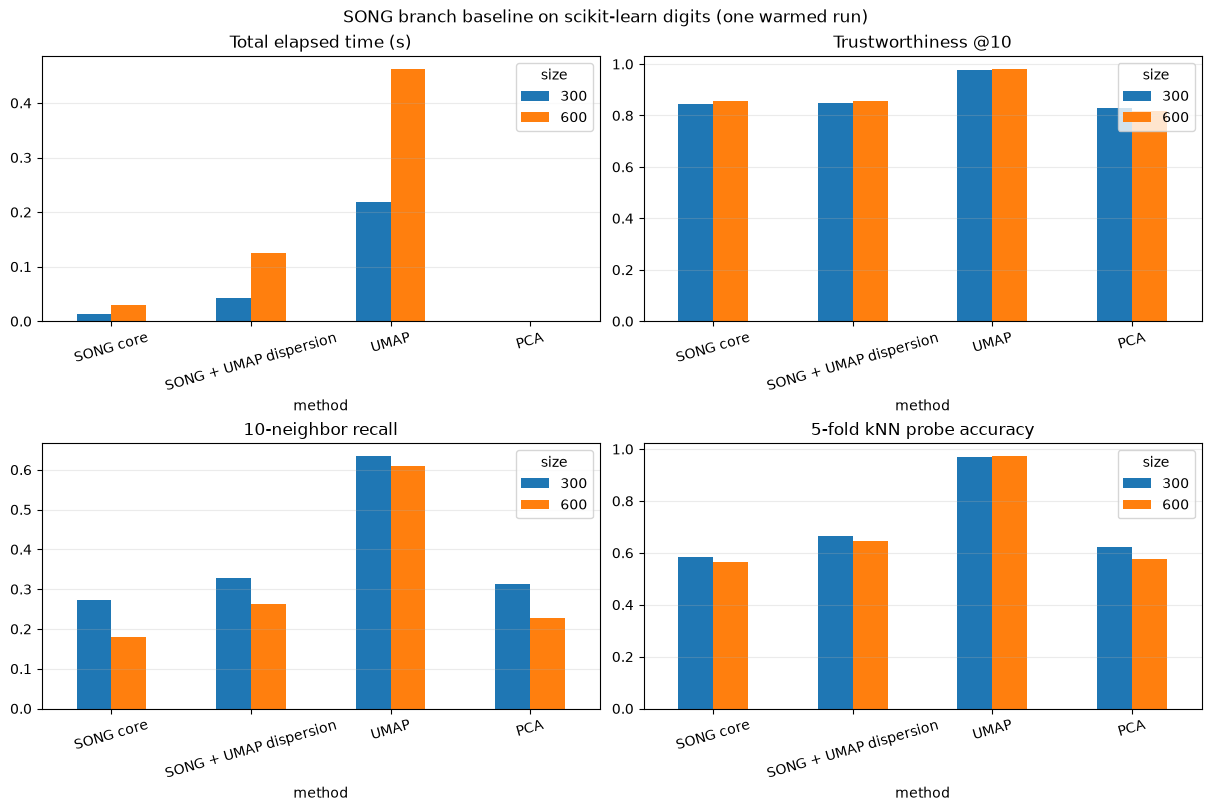

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8), constrained_layout=True)
for ax, metric, title in zip(axes.flat, ['total_s', 'trustworthiness', 'neighbor_recall_10', 'kNN_probe_accuracy'],
                             ['Total elapsed time (s)', 'Trustworthiness @10', '10-neighbor recall', '5-fold kNN probe accuracy']):
    pivot = results.pivot(index='method', columns='size', values=metric).loc[methods]
    pivot.plot.bar(ax=ax, rot=16, title=title)
    ax.grid(axis='y', alpha=.25)
fig.suptitle('SONG branch baseline on scikit-learn digits (one warmed run)')
fig.savefig(fig_dir / 'static_metrics.png', dpi=150)
plt.show()

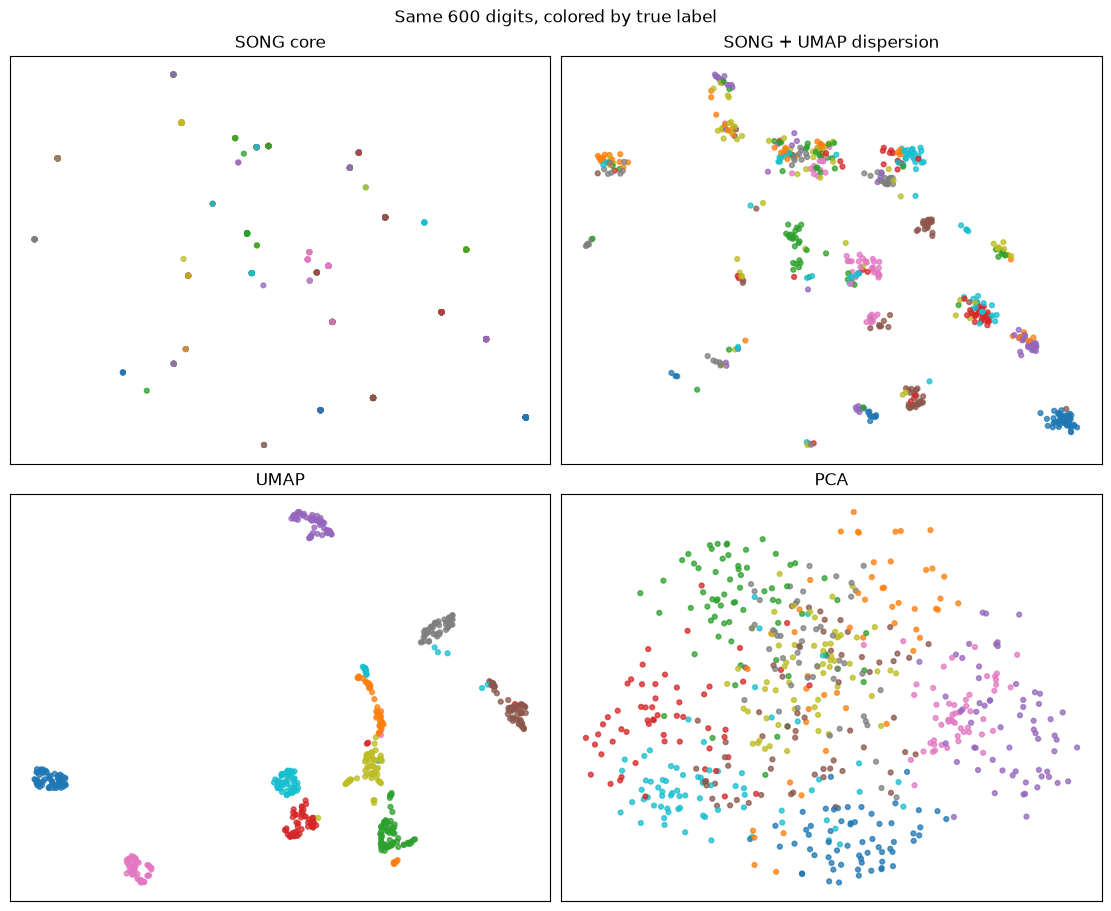

In [5]:
size = 600
labels = digits.target[indices[:size]]
fig, axes = plt.subplots(2, 2, figsize=(11, 9), constrained_layout=True)
for ax, method in zip(axes.flat, methods):
    Y = embeddings[(size, method)]
    ax.scatter(Y[:, 0], Y[:, 1], c=labels, cmap='tab10', s=12, alpha=.75, rasterized=True)
    ax.set_title(method)
    ax.set_xticks([]); ax.set_yticks([])
fig.suptitle('Same 600 digits, colored by true label')
fig.savefig(fig_dir / 'static_embeddings.png', dpi=150)
plt.show()

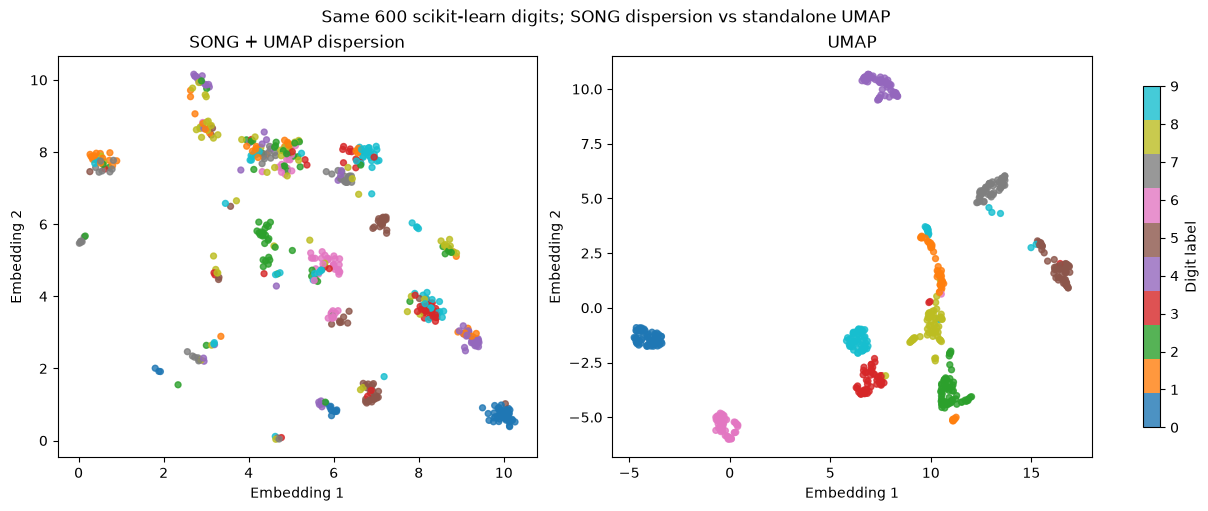

In [6]:
size = 600
labels = digits.target[indices[:size]]
fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)
for ax, method in zip(axes, ['SONG + UMAP dispersion', 'UMAP']):
    Y = embeddings[(size, method)]
    scatter = ax.scatter(Y[:, 0], Y[:, 1], c=labels, cmap='tab10', vmin=0, vmax=9,
                         s=18, alpha=.8, rasterized=True)
    ax.set_title(method)
    ax.set_xlabel('Embedding 1')
    ax.set_ylabel('Embedding 2')
fig.colorbar(scatter, ax=axes, ticks=range(10), label='Digit label', shrink=.85)
fig.suptitle('Same 600 scikit-learn digits; SONG dispersion vs standalone UMAP')
fig.savefig(fig_dir / 'umap_dispersion_vs_umap.png', dpi=180)
plt.show()

## Reading the result

Trustworthiness measures false neighbors introduced in 2D; neighbor recall measures retained original neighbors. ARI compares unsupervised k-means clusters with digit labels. The kNN probe is a lightweight label separability check, **not** SONG prediction accuracy. Timing includes SONG's `fit` and its `transform`; for the default dispersion mode, `transform` runs a fresh UMAP fit. First-import/JIT cost and peak memory are outside this benchmark. See the incremental notebook for a core behavior currently blocked by NumPy compatibility.